In [1]:
import wandb
import sys
import matplotlib.pyplot as plt
import scprep
import pandas as pd
sys.path.append('../hypgs/models')
from omegaconf import OmegaConf
from train_ae import load_data, make_model
import numpy as np
import os
import glob
import scanpy as sc
os.chdir('/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/hypergraph_scattering/hypgs/models')
from plotly3d.plot import scatter

In [2]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import pdist, squareform
import graphtools
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/torch_geometric/typing.py:54: UserWarning: An issue occurred while importing 'pyg-lib'. Disabling its usage. Stacktrace: /lib64/libm.so.6: version `GLIBC_2.29' not found (required by /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/libpyg.so)
  warnings.warn(f"An issue occurred while importing 'pyg-lib'. "
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/torch_geometric/typing.py:110: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /lib64/libm.so.6: version `GLIBC_2.29' not found (required by /gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/libpyg.so)
  warnings.warn(f"An issue occurred while importing 'torch-sparse'. "


In [3]:
# Initialize wandb (replace 'your_entity' and 'your_project' with your specific details)
wandb.login()
api = wandb.Api()

# Specify your entity, project, and sweep ID
entity = "xingzhis"
project = "dmae"
sweep_id = '4pwuqeh6'

# Fetch the sweep
sweep = api.sweep(f"{entity}/{project}/{sweep_id}")
run_ids = [run.id for run in sweep.runs]
folder_path = "wandb/"


Failed to detect the name of this notebook, you can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: Currently logged in as: xingzhis. Use `wandb login --relogin` to force relogin


In [4]:
# Initialize an empty list to store run data
runs_data = []

# Iterate through each run in the sweep
for run in sweep.runs:
    # Extract metrics and configs
    metrics = run.summary._json_dict
    configs = run.config
    
    # Combine metrics and configs, and add run ID
    combined_data = {**metrics, **configs, "run_id": run.id}
    
    # Append the combined data to the list
    runs_data.append(combined_data)

# Create a DataFrame from the runs data
df = pd.DataFrame(runs_data)
df_logpdist_recon = df.iloc[[i for i in df.index if df['model.dist_contr_recon_weights'][i] == [0.5, 0, 0.5]],:]


In [5]:
import torch
res = []
# run = [run for run in sweep.runs if run.id == 'bae5whsi'][0]
for idx in df_logpdist_recon['run_id']:
    run = [run for run in sweep.runs if run.id == idx][0]
    cfg = OmegaConf.create(run.config)
    folder_path = "wandb/"
    folder_list = glob.glob(f"{folder_path}*{run.id}*")
    ckpt_files = glob.glob(f"{folder_list[0]}/files/*.ckpt")
    ckpt_path = ckpt_files[0]
    trainloader, valloader, X, phate_coords, colors, dist = load_data(cfg)
    emb_dim = phate_coords.shape[1]
    data_path = os.path.join(cfg.data.root, cfg.data.name + cfg.data.filetype)
    data = np.load(data_path, allow_pickle=True)
    dist_std = np.std(data['dist'].flatten())
    model = make_model(cfg, X.shape[1], emb_dim, dist_std, from_checkpoint=True, checkpoint_path=ckpt_path)
    model.eval()
    x_all = torch.tensor(data['data'][data['is_train']]).float()
    x_pred, z_pred = model(x_all)
    x_pred = x_pred.detach().cpu().numpy()
    z_pred = z_pred.detach().cpu().numpy()
    section = cfg.data.name
    classes = np.load(f'../../data/hgsae/{section}_label.npy', allow_pickle=True)
    classes = classes[data['is_train']]
    res_dict = dict(
        z_pred=z_pred,
        classes=classes,
        section=section,
    )
    res.append(res_dict)
# scprep.plot.scatter2d(z_pred, title=section, ticks=False,c=classes, figsize=(10,10), s=50)

In [6]:
section_df = pd.read_csv('/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/sea_ad/data/hypergraphae/braak.csv')
section_dict = {section: braak for section, braak in zip(section_df['Section'], section_df['Braak'])}

/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/scprep/plot/utils.py:104: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be

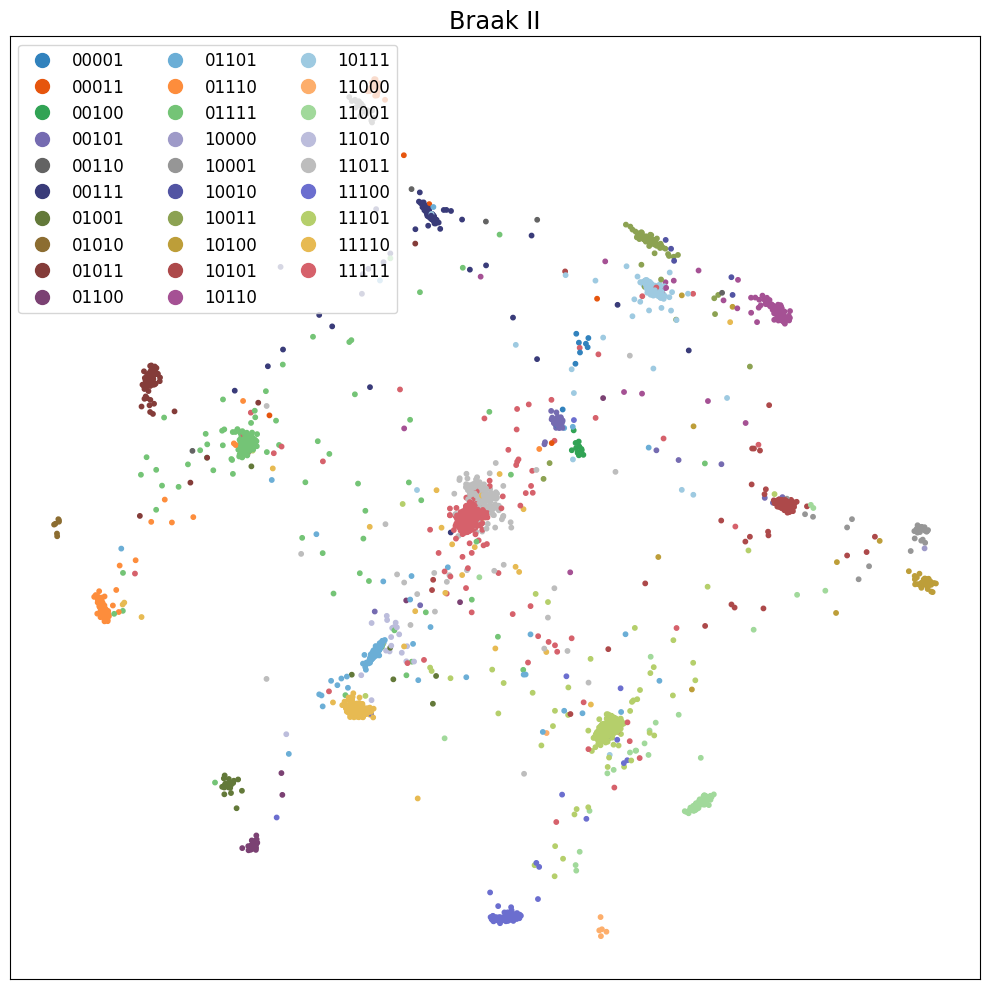

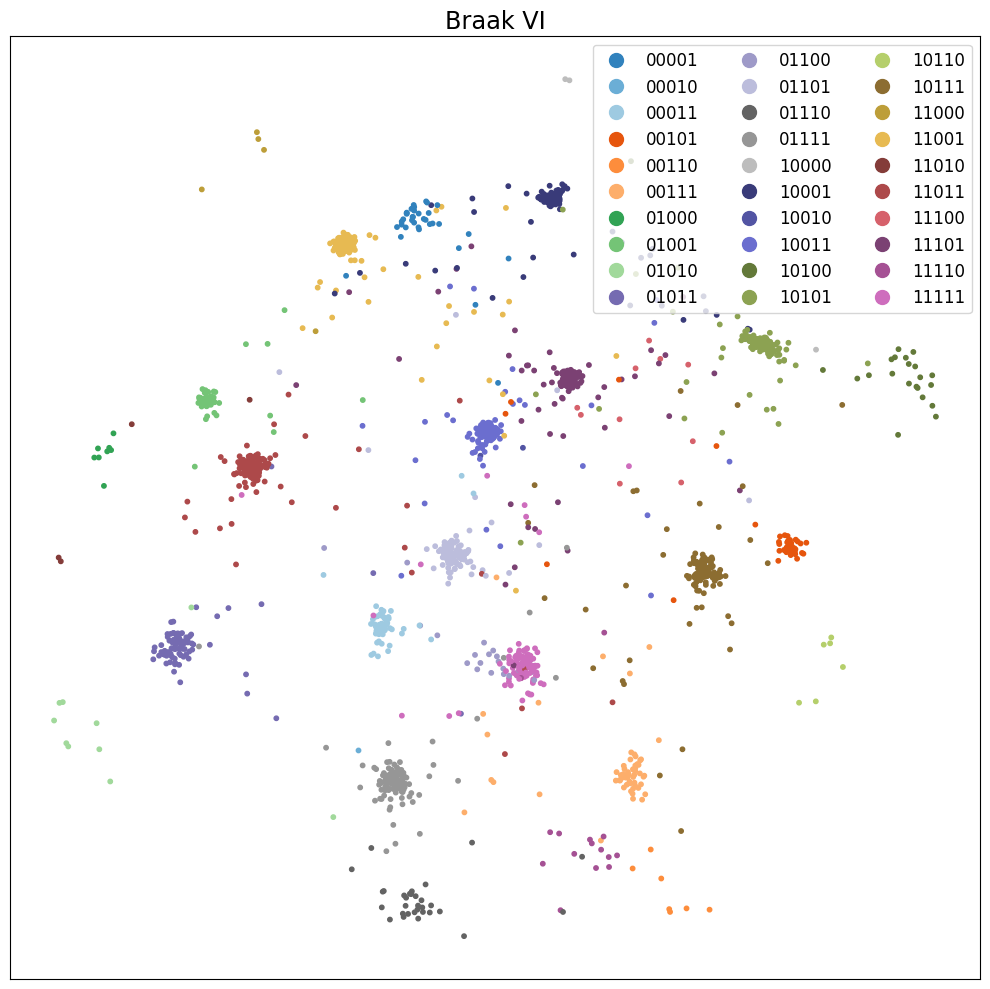

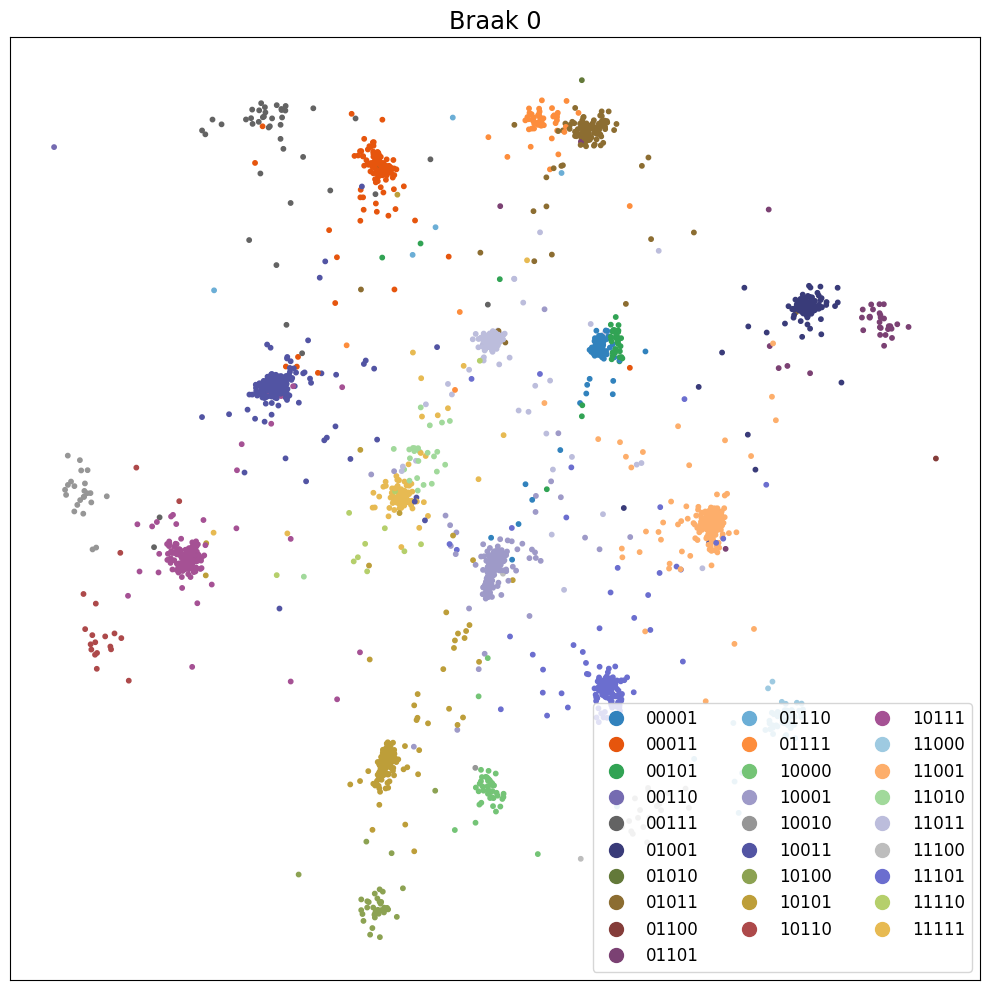

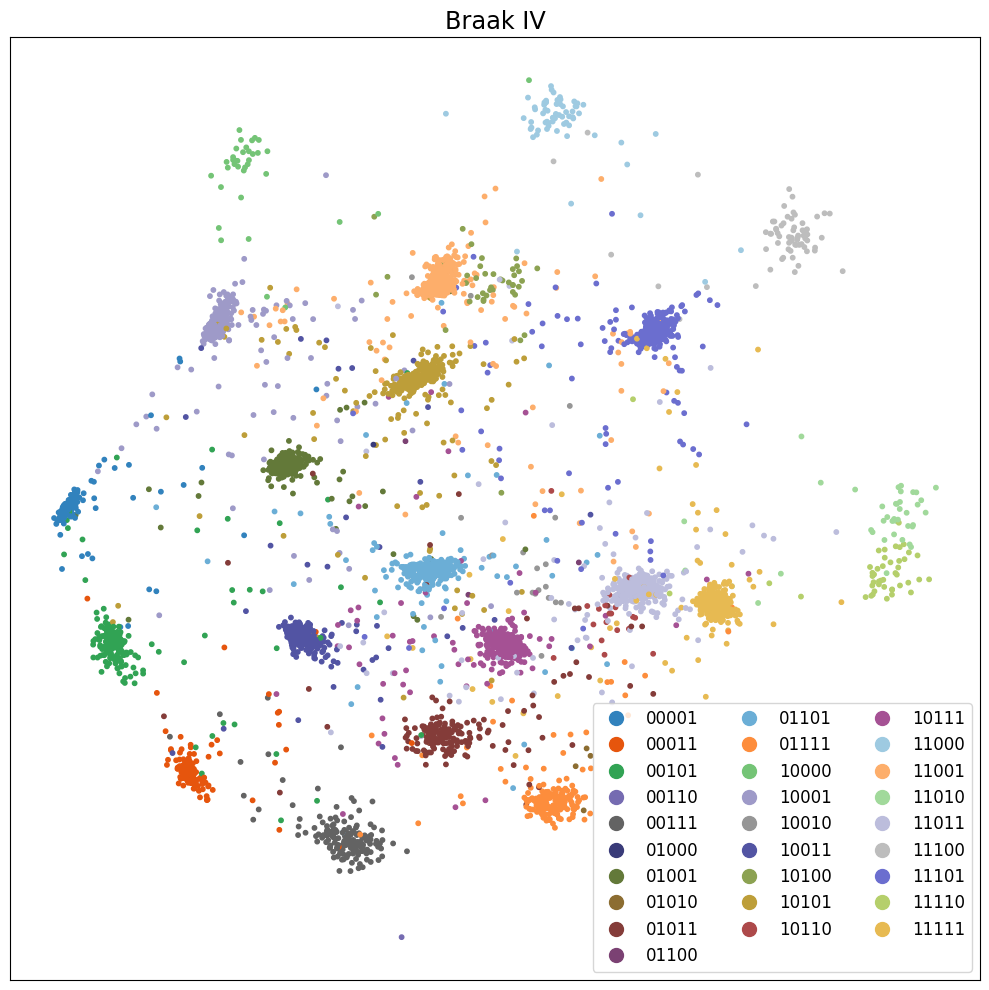

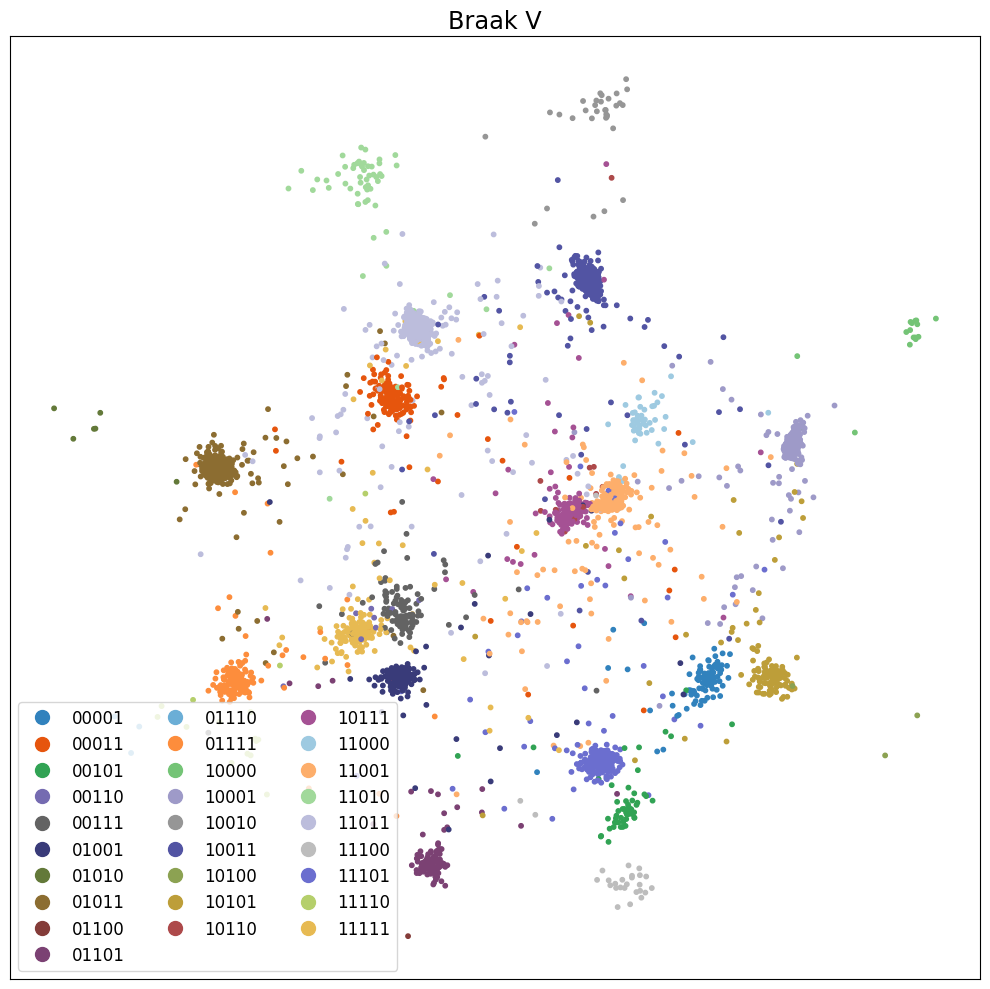

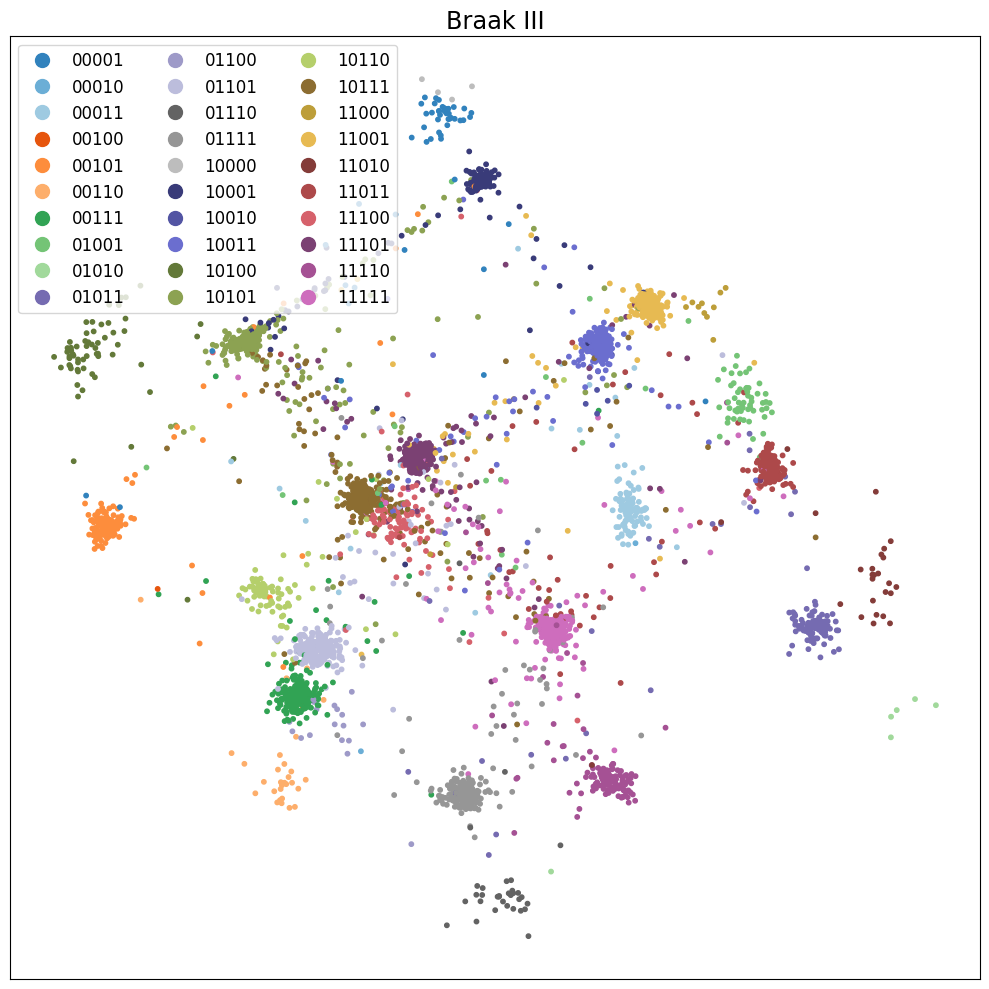

In [7]:
for res_dict in res:
    z_pred = res_dict['z_pred']
    classes = res_dict['classes']
    section = res_dict['section']
    braak = section_dict[section]
    scprep.plot.scatter2d(z_pred, title=braak, ticks=False,c=classes, figsize=(10,10), s=10)

In [8]:
res_dict = res[0]
z_pred = res_dict['z_pred']
classes = res_dict['classes']
section = res_dict['section']
braak = section_dict[section]
scatter(z_pred, title=braak, ticks=False,colors=classes, s=2, figsize=(10,10))

1. get cluster
2. get counts  
3. get graph
4. run GNN
5. aggregate

1. get cluster

In [9]:
X = z_pred
# Define the number of clusters
# n_clusters = 32

# Create an instance of the KMeans class
kmeans = KMeans(random_state=0)

# Fit the model to the data
kmeans.fit(X)

# Get the cluster labels for each data point
cluster_labels = kmeans.labels_



/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



In [10]:
scatter(X, cluster_labels)

2. get counts/frequencies

In [11]:
label_cluster_df = pd.DataFrame({'label': classes, 'cluster': cluster_labels})

In [12]:
label_cluster_table = pd.crosstab(label_cluster_df['label'], label_cluster_df['cluster']).T

In [13]:
label_cluster_table

label,00001,00011,00100,00101,00110,00111,01001,01010,01011,01100,...,10110,10111,11000,11001,11010,11011,11100,11101,11110,11111
cluster,,,,,,,,,,,,,,,,,,,,,
0,0,1,0,0,1,3,0,0,0,1,...,72,275,0,0,0,1,0,0,1,9
1,0,0,0,0,0,0,0,0,0,0,...,2,3,0,1,20,171,2,5,137,514
2,0,0,0,2,0,1,31,0,0,30,...,0,0,0,0,1,2,2,5,0,1
3,0,0,0,0,0,0,0,0,0,0,...,0,1,6,100,0,4,115,552,0,17
4,0,21,0,0,23,172,0,0,1,0,...,1,1,0,0,0,0,0,0,0,0
5,0,1,0,0,1,4,1,7,78,0,...,0,0,0,0,0,1,0,1,4,9
6,0,0,0,4,0,0,0,0,0,0,...,1,5,0,5,0,0,0,4,0,2
7,9,1,12,86,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
label_cluster_table_norm = label_cluster_table.div(label_cluster_table.sum(axis=1), axis=0)

In [15]:
label_cluster_table_norm

label,00001,00011,00100,00101,00110,00111,01001,01010,01011,01100,...,10110,10111,11000,11001,11010,11011,11100,11101,11110,11111
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.000000,0.002294,0.000000,0.000000,0.002294,0.006881,0.000000,0.000000,0.000000,0.002294,...,0.165138,0.630734,0.000000,0.000000,0.000000,0.002294,0.000000,0.000000,0.002294,0.020642
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.002299,0.003448,0.000000,0.001149,0.022989,0.196552,0.002299,0.005747,0.157471,0.590805
2,0.000000,0.000000,0.000000,0.004819,0.000000,0.002410,0.074699,0.000000,0.000000,0.072289,...,0.000000,0.000000,0.000000,0.000000,0.002410,0.004819,0.004819,0.012048,0.000000,0.002410
3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.001235,0.007407,0.123457,0.000000,0.004938,0.141975,0.681481,0.000000,0.020988
4,0.000000,0.092105,0.000000,0.000000,0.100877,0.754386,0.000000,0.000000,0.004386,0.000000,...,0.004386,0.004386,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.000000,0.001642,0.000000,0.000000,0.001642,0.006568,0.001642,0.011494,0.128079,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.001642,0.000000,0.001642,0.006568,0.014778
6,0.000000,0.000000,0.000000,0.013378,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.003344,0.016722,0.000000,0.016722,0.000000,0.000000,0.000000,0.013378,0.000000,0.006689
7,0.079646,0.008850,0.106195,0.761062,0.000000,0.017699,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


3. get distance kernel graph

In [16]:
centroids = kmeans.cluster_centers_

In [17]:
G = graphtools.Graph(centroids, knn=3, random_state=0)

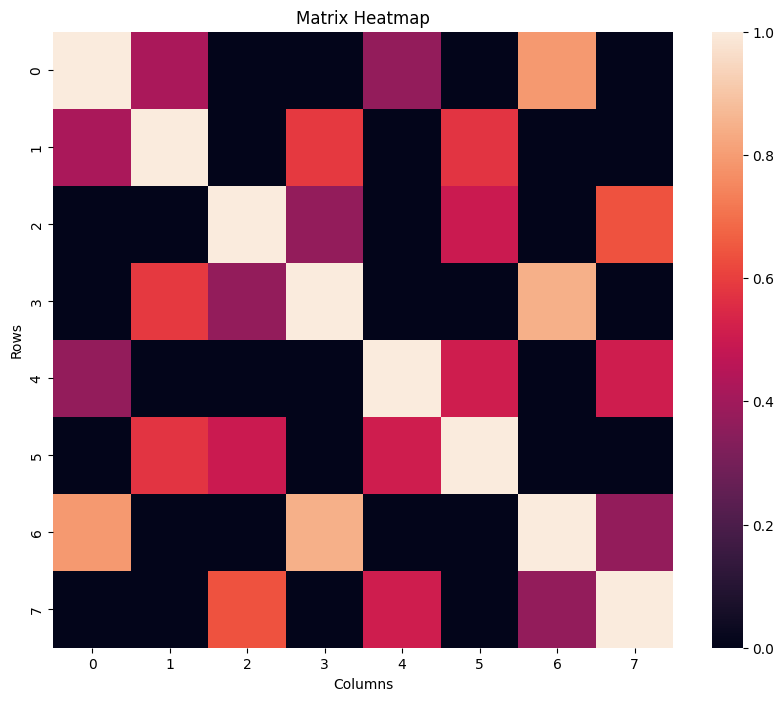

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a figure and axes
fig, ax = plt.subplots(figsize=(10, 8))

# Create the heatmap using seaborn
sns.heatmap(G.K.toarray(), ax=ax)

# Set the title and labels
ax.set_title('Matrix Heatmap')
aax.set_ylabel('Rows')

# Show the plot
plt.show()


In [19]:
G

In [20]:
import torch
import torch_geometric
import scipy.sparse as sp
from torch_geometric.data import Data

G_K = G.K

if not sp.isspmatrix_coo(G_K):
    G_K = sp.coo_matrix(G_K)

# Extract edges and weights from the sparse matrix
row = torch.tensor(G_K.row, dtype=torch.long)
col = torch.tensor(G_K.col, dtype=torch.long)
edge_index = torch.stack([row, col], dim=0)

# Edge weights
edge_weights = torch.tensor(G_K.data, dtype=torch.float)
x = torch.tensor(label_cluster_table_norm.values, dtype=torch.float)
# Create a PyTorch Geometric data object with edge attributes
data = Data(x=x, edge_index=edge_index, edge_attr=edge_weights.unsqueeze(1))


In [21]:
data

Data(x=[8, 29], edge_index=[2, 32], edge_attr=[32, 1])

4. propagete

In [22]:
class SimpleGNN(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(SimpleGNN, self).__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, output_dim)

    def forward(self, data):
        x, edge_index = data.x, data.edge_index

        # First graph convolution layer
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, training=self.training)

        # Second graph convolution layer
        x = self.conv2(x, edge_index)
        
        return x
        # return F.log_softmax(x, dim=1)

In [23]:
gnn = SimpleGNN(input_dim=data.x.size(1), hidden_dim=16, output_dim=16)

In [24]:
# conv1 = GCNConv(label_cluster_table_norm.shape[1], hidden_dim=16, out)

In [25]:
gnn(data).size()

torch.Size([8, 16])

In [26]:
data

Data(x=[8, 29], edge_index=[2, 32], edge_attr=[32, 1])

In [27]:
import torch
from torch_geometric.data import Data, DataLoader

# Assuming 'data' is your existing single graph data object

# Create a dataset by replicating 'data' multiple times
dataset = [data.clone() for _ in range(10)]  # Repeat data 10 times

# Initialize the DataLoader
loader = DataLoader(dataset, batch_size=2, shuffle=True)

# Example usage of the DataLoader
for batch_data in loader:
    print(batch_data)
    # You can pass batch_data to your model here
    # output = model(batch_data)
    # Compute loss, etc.


DataBatch(x=[16, 29], edge_index=[2, 64], edge_attr=[64, 1], batch=[16], ptr=[3])
DataBatch(x=[16, 29], edge_index=[2, 64], edge_attr=[64, 1], batch=[16], ptr=[3])
DataBatch(x=[16, 29], edge_index=[2, 64], edge_attr=[64, 1], batch=[16], ptr=[3])
DataBatch(x=[16, 29], edge_index=[2, 64], edge_attr=[64, 1], batch=[16], ptr=[3])
DataBatch(x=[16, 29], edge_index=[2, 64], edge_attr=[64, 1], batch=[16], ptr=[3])


/gpfs/gibbs/pi/krishnaswamy_smita/xingzhi/.conda_envs/geosink/lib/python3.11/site-packages/torch_geometric/deprecation.py:26: UserWarning:

'data.DataLoader' is deprecated, use 'loader.DataLoader' instead



In [45]:
import torch
import torch.nn.functional as F
from torch_scatter import scatter
from torch_geometric.nn import GCNConv
from torch.nn import Linear
from torch_geometric.data import Data

class StatisticalPooling(torch.nn.Module):
    def __init__(self):
        super(StatisticalPooling, self).__init__()

    def forward(self, x, batch):
        # Ensure 'batch' is not None and is properly sized
        if batch is None:
            raise ValueError("Batch tensor must not be None")

        # Mean
        mean = scatter(x, batch, dim=0, reduce='mean')

        # # Variance
        mean_sq = scatter(x**2, batch, dim=0, reduce='mean')
        variance = mean_sq - mean**2

        # # Correct the indexing for mean and variance when used
        mean_expanded = mean[batch]
        # variance_expanded = variance[batch]

        # # Skewness
        n = scatter(torch.ones_like(x[:, 0]), batch, dim=0, reduce='sum').unsqueeze(-1)  # number of elements per batch
        skewness = scatter((x - mean_expanded)**3, batch, dim=0, reduce='sum') / (n * (variance**1.5 + 1e-6))

        # # Kurtosis
        kurtosis = scatter((x - mean_expanded)**4, batch, dim=0, reduce='sum') / (n * (variance**2 + 1e-6)) - 3

        # # Concatenate all statistics to form a single vector per graph
        pooled_features = torch.cat([mean, variance, skewness, kurtosis], dim=1)
        # pooled_features = torch.cat([mean, variance, skewness], dim=1)
        return pooled_features



class GNNModel(torch.nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(GNNModel, self).__init__()
        self.conv1 = GCNConv(input_dim, hidden_dim)
        self.pool = StatisticalPooling()
        self.fc = Linear(hidden_dim * 4, output_dim)  # Adjust for concatenated stats

    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.pool(x, batch)  # Ensure batch is correctly passed
        x = self.fc(x)
        return x

# Dummy Data initialization and model usage can continue here


In [46]:
gnn = GNNModel(input_dim=data.x.size(1), hidden_dim=16, output_dim=6)

In [48]:
gnn(next(iter(loader)))

tensor([[ 1.9018, -0.3588,  1.6990, -0.6998,  0.1429, -0.3854],
        [ 1.9018, -0.3588,  1.6990, -0.6998,  0.1429, -0.3854]],
       grad_fn=<AddmmBackward0>)